# 第六章贷中信用风险预测模型代码

# 6.1 行为评分卡

# 6.2 案例：某信用卡业务行为评分卡构建

6.2.1 场景介绍

CreditBalance表则记录了每一个信用卡账户一年12期每一期的信用卡用款、还款、消费、逾期记录

6.2.2 数据整理与特征工程

取数数据

In [1]:
import pandas as pd
import numpy as np
Bal=pd.read_csv('data/CreditBalance.csv')
Label=pd.read_csv('data/label.csv')
Bal.query('Account_ID==41')

,Cust_ID,Account_ID,Period,Balance,Payment,Delq1,Delq2,Delq3,Spend
45,37,41,1,66848.17,0.0,1.0,0.0,0.0,121870.86
47568,37,41,2,188719.03,187897.0,0.0,0.0,0.0,50136.81
95091,37,41,3,50958.84,0.0,1.0,0.0,0.0,63462.02
142614,37,41,4,114420.86,114421.0,0.0,0.0,0.0,79049.79
190137,37,41,5,79049.65,0.0,1.0,0.0,0.0,15602.56
237660,37,41,6,94652.21,94653.0,0.0,0.0,0.0,42576.49
285183,37,41,7,42575.70,40285.0,0.0,0.0,0.0,75700.21
332706,37,41,8,77990.91,0.0,1.0,0.0,0.0,65581.16
380229,37,41,9,143572.07,114904.0,0.0,0.0,0.0,0.00
427752,37,41,10,28668.07,28669.0,0.0,0.0,0.0,64947.91


1.还款表现

In [2]:
def PaymentVar(Balance):
    """
    还款表现类特征
    """
    Bal=Balance.copy()
    
    ##还款表现特征
    VarSet={}
    
    #账户还款率:账单余额为0或负数时,返回np.nan,即该期还款率计为np.nan
    Bal['Pay_Ratio']=Bal['Payment']/Bal['Balance'].map(lambda x:np.nan if x<=0 else x)
    
    ## 还款率_金额_客户维度
    VarSet['Pay_Ratio_AVG_AMT']=Bal.groupby(['Cust_ID']).Pay_Ratio.mean().rename('Pay_Ratio_AVG_AMT')#期平均
    VarSet['Pay_Ratio_MAX_AMT']=Bal.groupby(['Cust_ID']).Pay_Ratio.max().rename('Pay_Ratio_MAX_AMT') #单期最大
    VarSet['Pay_Ratio_MIN_AMT']=Bal.groupby(['Cust_ID']).Pay_Ratio.min().rename('Pay_Ratio_MIN_AMT') #单期最小
    
    ## 还款率_金额_账户维度
    VarSet['Pay_Ratio_AVG_AMT_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Pay_Ratio.mean().groupby('Cust_ID').mean().rename('Pay_Ratio_AVG_AMT_ACC')    
    VarSet['Pay_Ratio_MAX_AMT_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Pay_Ratio.mean().groupby('Cust_ID').max().rename('Pay_Ratio_MAX_AMT_ACC') 
    VarSet['Pay_Ratio_MIN_AMT_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Pay_Ratio.mean().groupby('Cust_ID').min().rename('Pay_Ratio_MIN_AMT_ACC') 
    
    ## 还款率_账期_客户维度
    Bal['Pay_Flag']=Bal.apply(lambda x:0 if x['Payment']==0 and x['Balance']>0 else 1,1)
    VarSet['Pay_Ratio_Count']=Bal.groupby(['Cust_ID']).Pay_Flag.mean().rename('Pay_Ratio_Count')
    
    ## 还款率_账期_账户维度
    VarSet['Pay_Ratio_Count_AVG_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Pay_Flag.mean().groupby('Cust_ID').mean().rename('Pay_Ratio_Count_AVG_ACC')
    VarSet['Pay_Ratio_Count_MAX_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Pay_Flag.mean().groupby('Cust_ID').max().rename('Pay_Ratio_Count_MAX_ACC')
    VarSet['Pay_Ratio_Count_MIN_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Pay_Flag.mean().groupby('Cust_ID').min().rename('Pay_Ratio_Count_MIN_ACC')

    return(VarSet)

2.逾期情况

In [3]:
def DelqVar(Balance):
    """
    逾期类特征
    """
    Bal=Balance.copy()
    
    ##逾期类特征
    VarSet={}   
    
    #总逾期次数_客户维度
    VarSet['Delq1_Count']=Bal.groupby(['Cust_ID']).Delq1.sum().rename('Delq1_Count')
    VarSet['Delq2_Count']=Bal.groupby(['Cust_ID']).Delq2.sum().rename('Delq2_Count')
    VarSet['Delq3_Count']=Bal.groupby(['Cust_ID']).Delq3.sum().rename('Delq3_Count')
    
    #总逾期次数占比_客户维度
    VarSet['Delq1_Percent']=Bal.groupby(['Cust_ID']).Delq1.mean().rename('Delq1_Percent')
    VarSet['Delq2_Percent']=Bal.groupby(['Cust_ID']).Delq2.mean().rename('Delq2_Percent')
    VarSet['Delq3_Percent']=Bal.groupby(['Cust_ID']).Delq3.mean().rename('Delq3_Percent')
    
    #最高逾期状态_客户维度
    #20250503，将“1”改为“axis=1”
    VarSet['Delq_Status']=pd.concat(VarSet,axis=1).apply(
        lambda x:3 if x['Delq3_Percent']>0 else(
            2 if x['Delq2_Percent']>0 else(
                1 if x['Delq1_Percent']>0 else 0)
        ),1
    )
    
    #逾期账户数_账户维度
    VarSet['Delq1_Count_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Delq1.max().groupby('Cust_ID').sum().rename('Delq1_Count_ACC')
    VarSet['Delq2_Count_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Delq2.max().groupby('Cust_ID').sum().rename('Delq2_Count_ACC')
    VarSet['Delq3_Count_ACC']=Bal.groupby(['Cust_ID','Account_ID']).Delq3.max().groupby('Cust_ID').sum().rename('Delq3_Count_ACC')
    
    return(VarSet)

3.额度使用情况

In [4]:
def UseVar(BalanceWithLimit):
    """
    额度使用类特征
    """    
    Bal=BalanceWithLimit.copy()
    
    #当某期账单余额为0或负数时,该期账单余额使用率为np.nan
    Bal['Balance']=Bal['Balance'].map(lambda x:0 if x<0 else x)
    Bal['BillUseRate']=Bal['Balance']/Bal['Credit_Limit']
    Bal['SpendUseRate']=Bal['Spend']/Bal['Credit_Limit']
    
    ##额度使用类特征
    VarSet={}
    
    #1.使用率
    ##账单额度使用率_客户维度
    VarSet['BillUseRate_AVG']=Bal.groupby(['Cust_ID']).BillUseRate.mean().rename('BillUseRate_AVG')
    VarSet['BillUseRate_MAX']=Bal.groupby(['Cust_ID']).BillUseRate.max().rename('BillUseRate_MAX')
    VarSet['BillUseRate_MIN']=Bal.groupby(['Cust_ID']).BillUseRate.min().rename('BillUseRate_MIN')
    
    ##消费额度使用率_客户维度
    VarSet['SpendUseRate_AVG']=Bal.groupby(['Cust_ID']).SpendUseRate.mean().rename('SpendUseRate_AVG')
    VarSet['SpendUseRate_MAX']=Bal.groupby(['Cust_ID']).SpendUseRate.max().rename('SpendUseRate_MAX')
    VarSet['SpendUseRate_MIN']=Bal.groupby(['Cust_ID']).SpendUseRate.min().rename('SpendUseRate_MIN')
   
    ##账户平均账单额度使用率_账户维度
    BillUseRate_Acc=Bal.groupby(['Cust_ID','Account_ID']).BillUseRate.mean()
    VarSet['BillUseRate_AVG_ACC']=BillUseRate_Acc.groupby('Cust_ID').mean().rename('BillUseRate_AVG_ACC')
    VarSet['BillUseRate_MAX_ACC']=BillUseRate_Acc.groupby('Cust_ID').max().rename('BillUseRate_MAX_ACC')
    VarSet['BillUseRate_MIN_ACC']=BillUseRate_Acc.groupby('Cust_ID').min().rename('BillUseRate_MIN_ACC')
    
    ##账户平均消费额度使用率_账户维度
    SpendUseRate_Acc=Bal.groupby(['Cust_ID','Account_ID']).SpendUseRate.mean()
    VarSet['SpendUseRate_AVG_ACC']=SpendUseRate_Acc.groupby('Cust_ID').mean().rename('SpendUseRate_AVG_ACC')
    VarSet['SpendUseRate_MAX_ACC']=SpendUseRate_Acc.groupby('Cust_ID').max().rename('SpendUseRate_MAX_ACC')
    VarSet['SpendUseRate_MIN_ACC']=SpendUseRate_Acc.groupby('Cust_ID').min().rename('SpendUseRate_MIN_ACC')
    
    ##平均额度使用率大于0.75以上的账户数_账户维度
    VarSet['NumAcc_HighBillUseRate']=BillUseRate_Acc.map(lambda x:1 if x>0.75 else 0).groupby('Cust_ID').sum().rename('NumAcc_HighBillUseRate')
    VarSet['NumAcc_HighSpendUseRate']=SpendUseRate_Acc.map(lambda x:1 if x>0.75 else 0).groupby('Cust_ID').sum().rename('NumAcc_HighSpendUseRate')
    
    ##平均额度使用率小于0.5以下的账户数_账户维度
    VarSet['NumAcc_LowBillUseRate']=BillUseRate_Acc.map(lambda x:1 if x<0.5 else 0).groupby('Cust_ID').sum().rename('NumAcc_LowBillUseRate')
    VarSet['NumAcc_LowSpendUseRate']=SpendUseRate_Acc.map(lambda x:1 if x<0.5 else 0).groupby('Cust_ID').sum().rename('NumAcc_LowSpendUseRate')
    
    #2.趋势
    ##账单额度使用率趋势_账户维度:使用最晚期值/往期平滑值近似为趋势,大于1说明使用率趋势增加,小于1说明趋势减少,当分分母为0时(账单余额都为0)时,返回np.nan
    BillUseRate_Trend_ACC=Bal.set_index(['Cust_ID','Account_ID']).query('Period==12').BillUseRate/Bal.groupby(['Cust_ID','Account_ID']).BillUseRate.mean()
    VarSet['BillUseRate_Trend_MAX_ACC']=BillUseRate_Trend_ACC.groupby('Cust_ID').max().rename('BillUseRate_Trend_MAX_ACC')
    VarSet['BillUseRate_Trend_AVG_ACC']=BillUseRate_Trend_ACC.groupby('Cust_ID').mean().rename('BillUseRate_Trend_AVG_ACC')
    SpendUseRate_Trend_ACC=Bal.set_index(['Cust_ID','Account_ID']).query('Period==12').SpendUseRate/Bal.groupby(['Cust_ID','Account_ID']).SpendUseRate.mean()
    VarSet['SpendUseRate_Trend_MAX_ACC']=SpendUseRate_Trend_ACC.groupby('Cust_ID').max().rename('SpendUseRate_Trend_MAX_ACC')
    VarSet['SpendUseRate_Trend_AVG_ACC']=SpendUseRate_Trend_ACC.groupby('Cust_ID').mean().rename('SpendUseRate_Trend_AVG_ACC')
    
    #3.稳定性
    ##额度使用率稳定性_账户维度,当分分母为0时(账单余额都为0)时,稳定性为0
    BillUseRate_CV_ACC=(Bal.groupby(['Cust_ID','Account_ID']).BillUseRate.std()/Bal.groupby(['Cust_ID','Account_ID']).BillUseRate.mean()).map(lambda x:0 if x!=x else x)
    VarSet['BillUseRate_CV_AVG_ACC']=BillUseRate_CV_ACC.groupby('Cust_ID').mean().rename('BillUseRate_CV_AVG_ACC')
    VarSet['BillUseRate_CV_MAX_ACC']=BillUseRate_CV_ACC.groupby('Cust_ID').max().rename('BillUseRate_CV_MAX_ACC')
    VarSet['BillUseRate_CV_MIN_ACC']=BillUseRate_CV_ACC.groupby('Cust_ID').min().rename('BillUseRate_CV_MIN_ACC')
    SpendUseRate_CV_ACC=(Bal.groupby(['Cust_ID','Account_ID']).SpendUseRate.std()/Bal.groupby(['Cust_ID','Account_ID']).SpendUseRate.mean()).map(lambda x:0 if x!=x else x)
    VarSet['SpendUseRate_CV_AVG_ACC']=SpendUseRate_CV_ACC.groupby('Cust_ID').mean().rename('SpendUseRate_CV_AVG_ACC')
    VarSet['SpendUseRate_CV_AVGAVGMAX_ACC']=SpendUseRate_CV_ACC.groupby('Cust_ID').max().rename('SpendUseRate_CV_MAX_ACC')
    VarSet['SpendUseRate_CV_MIN_ACC']=SpendUseRate_CV_ACC.groupby('Cust_ID').min().rename('SpendUseRate_CV_MIN_ACC')
   
    ##账户账单余额稳定性_账户维度,当分分母为0时(账单余额都为0)时,稳定性为0
    Bal_CV_ACC=(Bal.groupby(['Cust_ID','Account_ID']).Balance.std()/Bal.groupby(['Cust_ID','Account_ID']).Balance.mean()).map(lambda x:0 if x!=x else x)
    VarSet['Balance_CV_Avg']=Bal_CV_ACC.groupby('Cust_ID').mean().rename('Balance_CV_Avg')
    VarSet['Balance_CV_Max']=Bal_CV_ACC.groupby('Cust_ID').max().rename('Balance_CV_Max')
    VarSet['Balance_CV_Min']=Bal_CV_ACC.groupby('Cust_ID').min().rename('Balance_CV_Min')
    
    ##消费额稳定性_账户维度,当分分母为0时(消费额都为0)时,稳定性为0
    Spend_CV_ACC=(Bal.groupby(['Cust_ID','Account_ID']).Spend.std()/Bal.groupby(['Cust_ID','Account_ID']).Spend.mean()).map(lambda x:0 if x!=x else x)
    VarSet['Spend_CV_Avg']=Bal_CV_ACC.groupby('Cust_ID').mean().rename('Spend_CV_Avg')
    VarSet['Spend_CV_Max']=Bal_CV_ACC.groupby('Cust_ID').max().rename('Spend_CV_Max')
    VarSet['Spend_CV_Min']=Bal_CV_ACC.groupby('Cust_ID').min().rename('Spend_CV_Min')
      
    return(VarSet)

4.账户信息

In [5]:
def AccountInfo(Label):
    """
    账户类基本信息
    """    
    lab=Label.copy()
    
    VarSet={}
    
    #账户信息_客户维度
    VarSet['NumAcc']=lab.groupby('Cust_ID').Account_ID.count().rename('NumAcc')
    VarSet['CreditLimit_SUM']=lab.groupby('Cust_ID').Credit_Limit.sum().rename('CreditLimit_SUM')
    VarSet['CreditLimit_MAX']=lab.groupby('Cust_ID').Credit_Limit.max().rename('CreditLimit_MAX')
    VarSet['CreditLimit_MIN']=lab.groupby('Cust_ID').Credit_Limit.min().rename('CreditLimit_MIN')
    
    #目标信息_客户维度,当客户某账户定义为坏即认定该客户为坏客户
    VarSet['Target']=lab.groupby('Cust_ID').label.max().rename('Target')
    
    return(VarSet)

5.构建宽表

In [6]:
import pandas as pd
import numpy as np

def ABT(Bal,Label):
    """
    形成建模宽表,回溯期选为3,6,12个月
    """
    AllData=pd.DataFrame()
    Bal_1=Bal.merge(Label[['Account_ID','Credit_Limit']],on='Account_ID')
    
   
      
    PaymentVar_temp=pd.DataFrame()   # 20250503增加，3.12与3.8的差异导致
    DelqVar_temp=pd.DataFrame()      # 20250503增加，3.12与3.8的差异导致
    UseVar_temp=pd.DataFrame()       # 20250503增加，3.12与3.8的差异导致
    AccountInfo_temp=pd.DataFrame()  # 20250503增加，3.12与3.8的差异导致
   

    for T in [3,6,12]:
        #1.还款表现类特征
        #PaymentVar_temp=pd.concat([PaymentVar_temp,PaymentVar(Bal[Bal.Period.isin([i for i in range(12,12-T,-1)])])],axis=1)
        #20250503增加pd.DataFrame转换
        PaymentVar_temp=pd.concat([PaymentVar_temp,pd.DataFrame(PaymentVar(Bal[Bal.Period.isin([i for i in range(12,12-T,-1)])]))],axis=1)
        PaymentVar_temp.columns=PaymentVar_temp.columns+'_L'+str(T)+'M'
                
        #2.逾期类特征
        #DelqVar_temp=pd.concat([DelqVar_temp,DelqVar(Bal[Bal.Period.isin([i for i in range(12,12-T,-1)])])],axis=1)
        #20250503增加pd.DataFrame转换
        #DelqVar_temp=pd.concat([DelqVar_temp,DelqVar(Bal[Bal.Period.isin([i for i in range(12,12-T,-1)])])],axis=1)

        DelqVar_temp=pd.concat([DelqVar_temp,pd.DataFrame(DelqVar(Bal[Bal.Period.isin([i for i in range(12,12-T,-1)])]))],axis=1)
        DelqVar_temp.columns=DelqVar_temp.columns+'_L'+str(T)+'M'

        #3.额度使用类特征
        #20250503增加pd.DataFrame转换
        UseVar_temp=pd.concat([UseVar_temp,pd.DataFrame(UseVar(Bal_1[Bal_1.Period.isin([i for i in range(12,12-T,-1)])]))],axis=1) 
        UseVar_temp.columns=UseVar_temp.columns+'_L'+str(T)+'M'
        AllData=pd.concat([AllData,PaymentVar_temp,DelqVar_temp,UseVar_temp],axis=1) #20250503，将“1”改为“axis=1”
    #4.账户信息类特征
    AccountInfo_temp=pd.concat([AccountInfo_temp,pd.DataFrame(AccountInfo(Label))],axis=1) #20250503，将“1”改为“axis=1”，同时增加pd.DataFrame
    AllData=pd.concat([AllData,AccountInfo_temp],axis=1) #20250503，将“1”改为“axis=1”
    
    return(AllData)

Bal=pd.read_csv('data/CreditBalance.csv')
Label=pd.read_csv('data/label.csv')
dat =ABT(Bal,Label)

In [8]:
#dat.to_csv('out/AllData20241231.csv')

6.2.3 数据清洗与特征初筛

1. 数据清洗与数据质量报告

In [9]:
for i in dat.columns:
    dat[i]=dat[i].astype('float')
    
missing_values_num=[np.nan,np.inf,-np.inf]
missing_values_obj=[np.nan,'nan','','special','missing']
dat=pd.concat(
    [
dat.select_dtypes(include='number').replace(missing_values_num,-9999), dat.select_dtypes(exclude='number').replace(missing_values_obj,'missing'),],axis=1
)

数据质量报告

In [10]:
import toad
toad.detect(dat)

,type,size,missing,unique,mean_or_top1,std_or_top2,min_or_top3,1%_or_top4,10%_or_top5,50%_or_bottom5,75%_or_bottom4,90%_or_bottom3,99%_or_bottom2,max_or_bottom1
Pay_Ratio_AVG_AMT_L3M,float64,40142,0.00%,37719,-1.685883,149.713132,-9999.0,0.0,0.253948,0.590157,0.666701,0.955366,1.000021,1.372653e+00
Pay_Ratio_MAX_AMT_L3M,float64,40142,0.00%,37514,-1.346579,149.718165,-9999.0,0.0,0.735294,1.000003,1.000011,1.000026,1.000243,2.127660e+00
Pay_Ratio_MIN_AMT_L3M,float64,40142,0.00%,8876,-2.050723,149.707864,-9999.0,0.0,0.000000,0.000000,0.000000,0.887276,1.000010,1.000530e+00
Pay_Ratio_AVG_AMT_ACC_L3M,float64,40142,0.00%,37719,-1.685347,149.713140,-9999.0,0.0,0.254111,0.590571,0.666703,0.955435,1.000021,1.372653e+00
Pay_Ratio_MAX_AMT_ACC_L3M,float64,40142,0.00%,37712,-1.660620,149.713526,-9999.0,0.0,0.259767,0.608339,0.833867,0.972726,1.000028,1.372653e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NumAcc,float64,40142,0.00%,10,1.183872,0.482261,1.0,1.0,1.000000,1.000000,1.000000,2.000000,3.000000,1.200000e+01
CreditLimit_SUM,float64,40142,0.00%,415,161333.249464,109007.713489,10000.0,40000.0,70000.000000,140000.000000,200000.000000,280000.000000,500000.000000,3.000000e+06
CreditLimit_MAX,float64,40142,0.00%,352,145619.298989,86004.962685,10000.0,40000.0,60000.000000,130000.000000,180000.000000,250000.000000,420000.000000,2.660000e+06
CreditLimit_MIN,float64,40142,0.00%,357,134789.240696,82588.936790,10000.0,20000.0,50000.000000,120000.000000,170000.000000,220000.000000,400000.000000,2.000000e+06


2. 数据分区与特征初筛

In [11]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
	dat.drop('Target',axis=1),
	dat['Target'],
	test_size=0.33,
	random_state=1234,
	stratify=dat['Target'])

6.2.4 分箱与WOE编码

In [12]:
bins = toad.transform.Combiner()
bins.fit(X_train,y_train, method = 'dt',n_bins=5,min_samples = 0.05)
woe = toad.transform.WOETransformer()
X_train_woe = woe.fit_transform(bins.transform(X_train), y_train)
X_test_woe = woe.transform(bins.transform(X_test))

6.2.5 相关性筛选

In [13]:
X_train_woe_1=toad.selection.drop_corr(X_train_woe,y_train,0.6)
X_test_woe_1=X_test_woe[X_train_woe_1.columns]

6.2.6 逐步回归建模

In [14]:
X_train_woe_2 = toad.selection.stepwise(X_train_woe_1,y_train,
direction = 'both', criterion = 'aic')
X_test_woe_2 = X_test_woe_1[X_train_woe_2.columns]

6.2.7 模型评估

1. 入模特征

2. 样本内评估

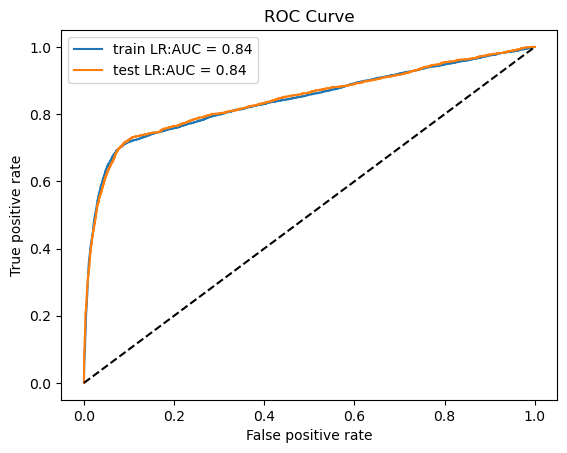

In [15]:
import sklearn.metrics as metrics
#from matplotlib import pyplot as plt  
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train_woe_2,y_train)
fpr_train, tpr_train,_ = metrics.roc_curve(y_train, model.predict_proba(X_train_woe_2)[:,1])
fpr_test, tpr_test,_ = metrics.roc_curve(y_test, model.predict_proba(X_test_woe_2)[:,1])
plt.plot(fpr_train,tpr_train,label = 'train LR:AUC = %0.2f'% metrics.auc(fpr_train, tpr_train)) 
plt.plot(fpr_test,tpr_test,label = 'test LR:AUC = %0.2f'% metrics.auc(fpr_test, tpr_test)) 
plt.plot([0,1],[0,1],'k--')  
plt.xlabel('False positive rate')  
plt.ylabel('True positive rate')  
plt.title('ROC Curve')  
plt.legend(loc = 'best') 